In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

In [3]:
hfdataset= HFDatasetLoader(dataset_name="aptologia/precios-arriendo-colombia", split="train", filename="datos/precios-arriendo-colombia.csv")

In [4]:
df = hfdataset.load()

In [5]:
df.head(2)


,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841


## Regresion Lineal Simple

In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np

X, y = df[["con_parqueadero"]], df["mediana"] # preparar datos
modelo = LinearRegression() #inicializar modelo

X_train, X_test, y_train, y_test = train_test_split( #dividir_datos
    X, y, test_size=0.2, random_state=42
)

modelo.fit(X_train, y_train)# entrenamiento
predicciones = modelo.predict(X_test) # prediccion
w = modelo.coef_[0]
b = modelo.intercept_

print(f"MAE: {mean_absolute_error(y_test, predicciones):.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicciones)):.2f}")
print(f"R2: {r2_score(y_test, predicciones):.2f}")
print(f"w: {w:.2f}")
print(f"b: {b:.2f}")

MAE: 1708817.96
RMSE: 2727148.36
R2: 0.00
w: 561.88
b: 2974320.71


In [7]:
%pip install --upgrade matplotlib

Note: you may need to restart the kernel to use updated packages.


In [8]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [9]:
%matplotlib inline

In [10]:
import sys
import matplotlib

print(sys.executable)
print(matplotlib.__version__)

c:\Users\user\Documents\Disco duro\Univerisidad\Machine Learning\ML_202604_Santiago_Lopez_F\.venv\Scripts\python.exe
3.11.2


In [11]:
import matplotlib.pyplot as plt
from IPython.display import display

x_test = X_test["con_parqueadero"].to_numpy()
y_test_array = y_test.to_numpy()
orden = x_test.argsort()


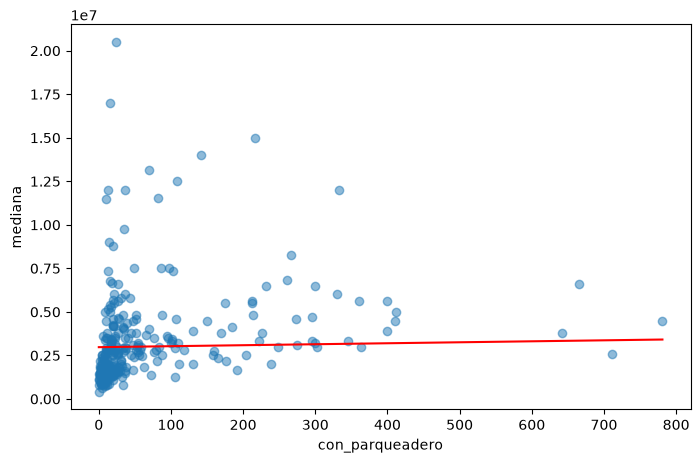

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    x_test,
    y_test_array,
    alpha=0.5,
)

ax.plot(
    x_test[orden],
    predicciones[orden],
    color="red",
)

ax.set_xlabel("con_parqueadero")
ax.set_ylabel("mediana")

display(fig)
plt.close(fig)

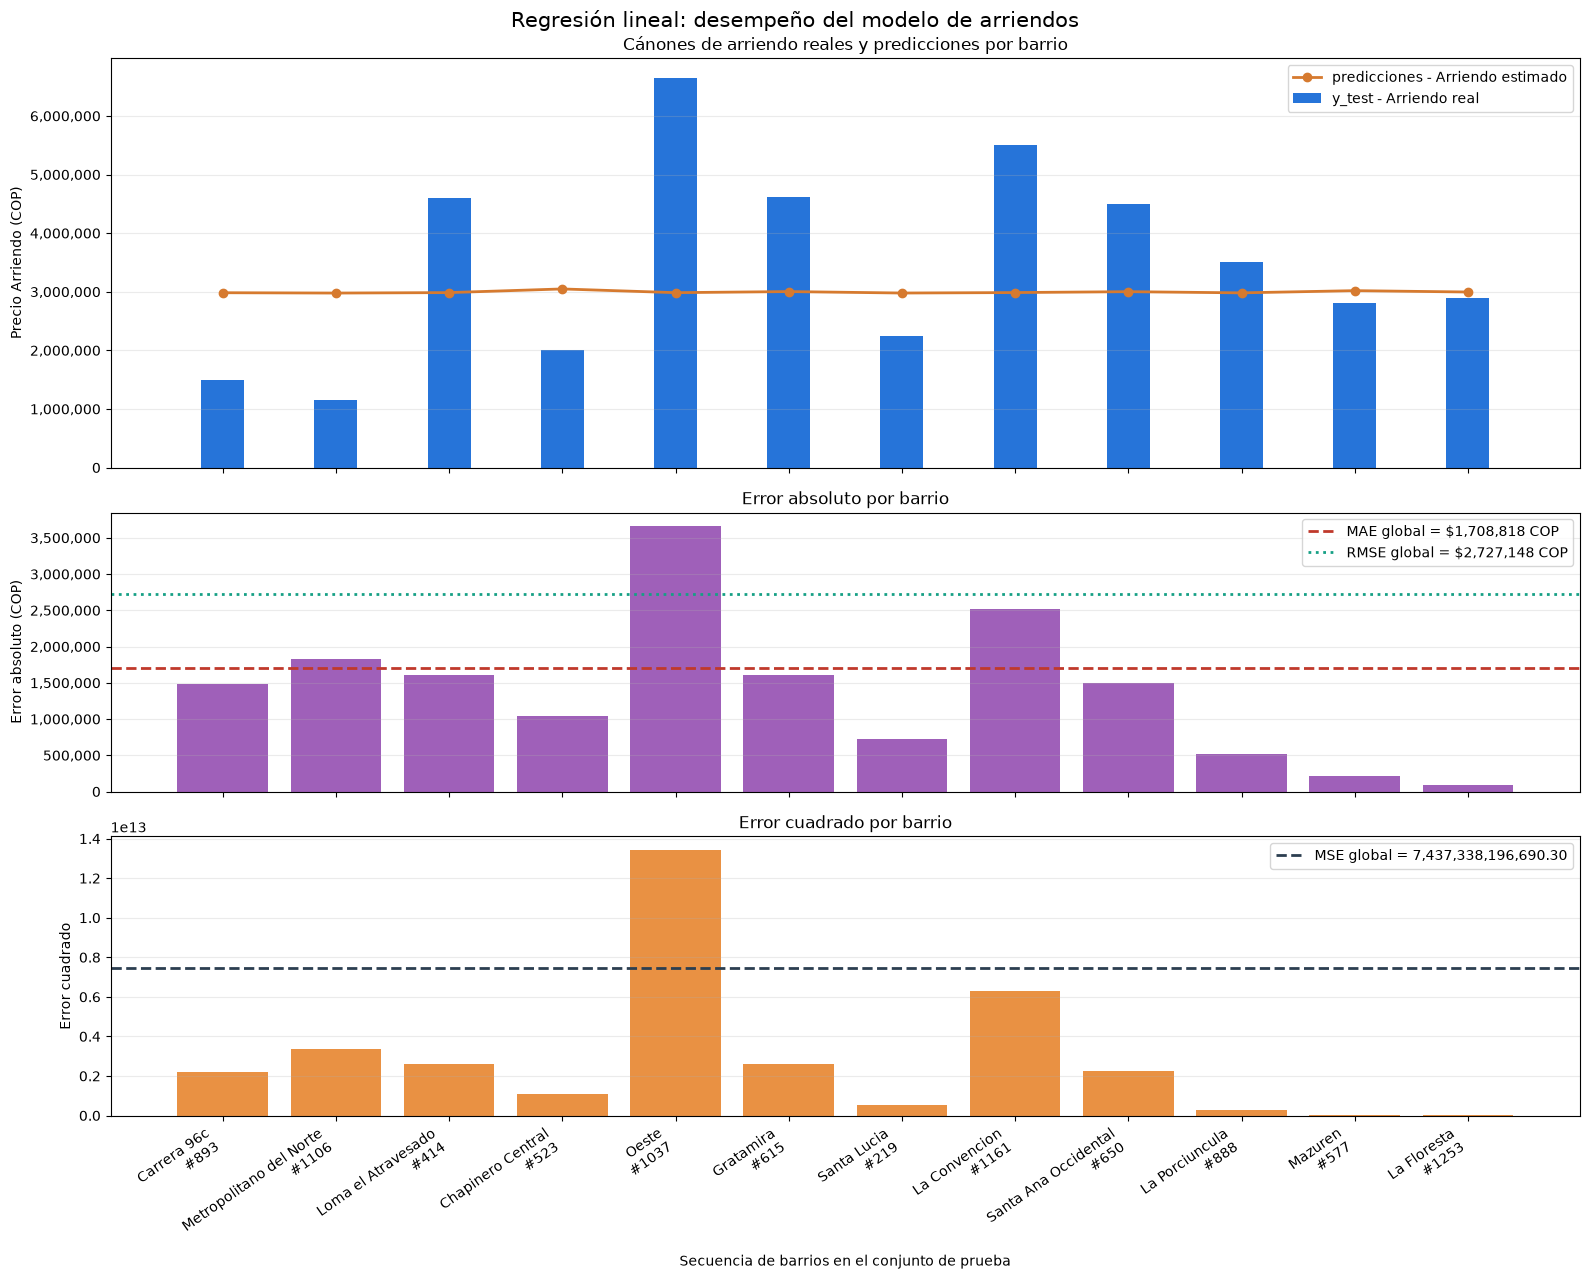

Barrios mostrados: 12 de 292
Métricas globales - MAE: $1,708,817.96 COP; RMSE: $2,727,148.36 COP; MSE: 7,437,338,196,690.30
Métricas de la selección - MAE: $1,401,676.74 COP; RMSE: $1,700,159.14 COP; MSE: 2,890,541,094,454.10


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Comparación combinada para una selección legible de barrios/sectores
indices_test = y_test.index.to_numpy()
y_test_array = y_test.to_numpy()
predicciones_array = np.asarray(predicciones)

# Se muestran hasta 12 barrios, manteniendo el orden del conjunto de prueba
seleccion = np.arange(min(12, len(y_test_array)))
y_real = y_test_array[seleccion]
y_predicha = predicciones_array[seleccion]

errores = y_real - y_predicha
error_absoluto = np.abs(errores)
error_cuadrado = errores ** 2

# Etiquetas usando 'barrio' de tu dataset (o barrio + ciudad/fecha)
etiquetas = [
    f"{df.loc[indices_test[i], 'barrio']}\n#{indices_test[i] + 1}"
    for i in seleccion
]

# Métricas globales
mae_global = mean_absolute_error(y_test_array, predicciones_array)
rmse_global = np.sqrt(mean_squared_error(y_test_array, predicciones_array))
mse_global = mean_squared_error(y_test_array, predicciones_array)

posiciones = np.arange(len(seleccion))
ancho = 0.38

fig, (ax_precios, ax_absoluto, ax_cuadrado) = plt.subplots(
    3, 1, figsize=(16, 13), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.5, 1.5]},
)

# 1. Gráfica superior: Canon real vs Canon estimado
ax_precios.bar(posiciones, y_real, ancho, label="y_test - Arriendo real", color="#2674d9")
ax_precios.plot(posiciones, y_predicha, color="#d67a2f", marker="o", linewidth=2,
                label="predicciones - Arriendo estimado")
ax_precios.set_ylabel("Precio Arriendo (COP)")
ax_precios.set_title("Cánones de arriendo reales y predicciones por barrio")
ax_precios.legend()
ax_precios.grid(axis="y", alpha=0.25)

# Formatear el eje Y de precios para mostrar con comas o millones
ax_precios.yaxis.set_major_formatter('{x:,.0f}')

# 2. Gráfica intermedia: Errores absolutos por barrio
ax_absoluto.bar(posiciones, error_absoluto, color="#8e44ad", alpha=0.85)
ax_absoluto.axhline(mae_global, color="#c0392b", linestyle="--", linewidth=2,
                    label=f"MAE global = ${mae_global:,.0f} COP")
ax_absoluto.axhline(rmse_global, color="#16a085", linestyle=":", linewidth=2,
                    label=f"RMSE global = ${rmse_global:,.0f} COP")
ax_absoluto.set_ylabel("Error absoluto (COP)")
ax_absoluto.set_title("Error absoluto por barrio")
ax_absoluto.legend()
ax_absoluto.grid(axis="y", alpha=0.25)
ax_absoluto.yaxis.set_major_formatter('{x:,.0f}')

# 3. Gráfica inferior: Errores cuadrados
ax_cuadrado.bar(posiciones, error_cuadrado, color="#e67e22", alpha=0.85)
ax_cuadrado.axhline(mse_global, color="#2c3e50", linestyle="--", linewidth=2,
                    label=f"MSE global = {mse_global:,.2f}")
ax_cuadrado.set_ylabel("Error cuadrado")
ax_cuadrado.set_title("Error cuadrado por barrio")
ax_cuadrado.legend()
ax_cuadrado.grid(axis="y", alpha=0.25)
ax_cuadrado.set_xticks(posiciones)
ax_cuadrado.set_xticklabels(etiquetas, rotation=35, ha="right")
ax_cuadrado.set_xlabel("Secuencia de barrios en el conjunto de prueba")

fig.suptitle("Regresión lineal: desempeño del modelo de arriendos", fontsize=15)
fig.tight_layout()

display(fig)
plt.close(fig)

# Impresión de métricas
print(f"Barrios mostrados: {len(seleccion)} de {len(y_test_array)}")
print(f"Métricas globales - MAE: ${mae_global:,.2f} COP; RMSE: ${rmse_global:,.2f} COP; MSE: {mse_global:,.2f}")
print(f"Métricas de la selección - MAE: ${error_absoluto.mean():,.2f} COP; RMSE: ${np.sqrt(error_cuadrado.mean()):,.2f} COP; MSE: {error_cuadrado.mean():,.2f}")

Filas: 1460 | duplicados exactos: 0
Valores faltantes por columna:
Sin valores faltantes


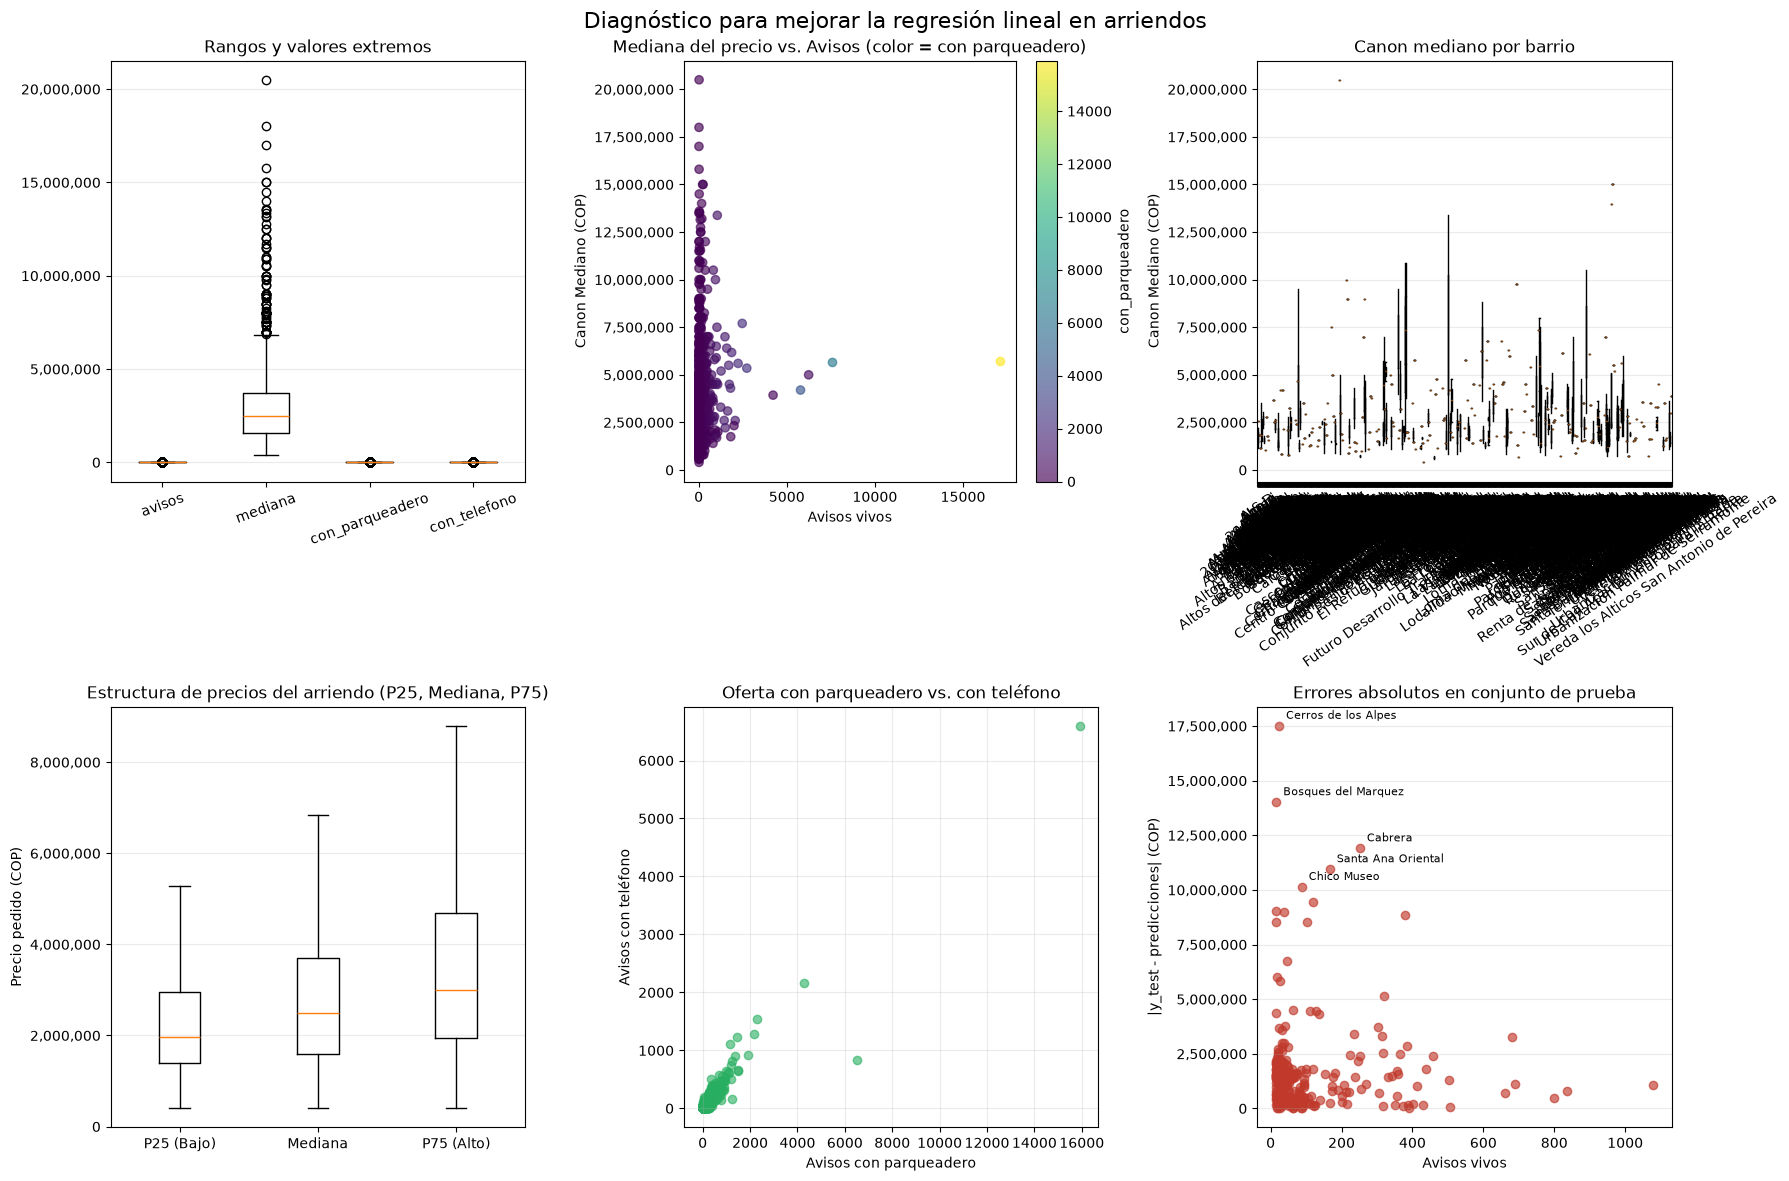


Mayores errores absolutos del conjunto de prueba:
                  barrio  avisos  con_parqueadero    y_test  predicciones  error_absoluto
806  Cerros de los Alpes      24               24  20500000  2.987806e+06    1.751219e+07
894  Bosques del Marquez      16               16  17000000  2.983311e+06    1.401669e+07
538              Cabrera     252              217  15000000  3.096248e+06    1.190375e+07
558   Santa Ana Oriental     167              141  14000000  3.053545e+06    1.094645e+07
598          Chico Museo      88               70  13150000  3.013652e+06    1.013635e+07

Cobertura de categorías:
ciudad: 17 categorías | mínimo por categoría: 1
barrio: 1300 categorías | mínimo por categoría: 1


In [14]:
# Diagnóstico visual para decidir cómo mejorar el modelo de arriendos
columnas_requeridas = [
    "fecha", "ciudad_id", "ciudad", "barrio", "avisos",
    "p25", "mediana", "p75", "con_parqueadero", "con_telefono"
]

columnas_disponibles = [columna for columna in columnas_requeridas if columna in df.columns]
filas_duplicadas = int(df.duplicated().sum())
valores_faltantes = df[columnas_disponibles].isna().sum()

print(f"Filas: {len(df)} | duplicados exactos: {filas_duplicadas}")
print("Valores faltantes por columna:")
print(valores_faltantes[valores_faltantes > 0] if valores_faltantes.any() else "Sin valores faltantes")

# Preparar la información del conjunto de prueba para investigar errores
indices_test = y_test.index.to_numpy()
prueba = df.loc[indices_test, columnas_disponibles].copy(deep=True)
prueba["y_test"] = y_test.to_numpy()
prueba["predicciones"] = np.asarray(predicciones)
prueba.loc[:, "error_absoluto"] = np.abs(prueba["y_test"] - prueba["predicciones"])
prueba.loc[:, "error_cuadrado"] = (prueba["y_test"] - prueba["predicciones"]) ** 2

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Revisar rangos y posibles valores extremos en las variables numéricas
axes[0, 0].boxplot(
    [df["avisos"].dropna(), df["mediana"].dropna(), df["con_parqueadero"].dropna(), df["con_telefono"].dropna()],
    tick_labels=["avisos", "mediana", "con_parqueadero", "con_telefono"],
    showfliers=True
)
axes[0, 0].set_title("Rangos y valores extremos")
axes[0, 0].tick_params(axis="x", rotation=20)
axes[0, 0].grid(axis="y", alpha=0.25)
axes[0, 0].yaxis.set_major_formatter('{x:,.0f}')

# 2. Precio mediano vs. número de avisos, coloreado por cantidad de parqueaderos
scatter = axes[0, 1].scatter(
    df["avisos"], df["mediana"], c=df["con_parqueadero"], cmap="viridis", alpha=0.65
)
axes[0, 1].set_title("Mediana del precio vs. Avisos (color = con parqueadero)")
axes[0, 1].set_xlabel("Avisos vivos")
axes[0, 1].set_ylabel("Canon Mediano (COP)")
axes[0, 1].yaxis.set_major_formatter('{x:,.0f}')
fig.colorbar(scatter, ax=axes[0, 1], label="con_parqueadero")

# 3. Comparar distribución del precio mediano entre los barrios
barrios = sorted(df["barrio"].dropna().unique())
axes[0, 2].boxplot(
    [df.loc[df["barrio"] == barrio, "mediana"].dropna() for barrio in barrios],
    tick_labels=barrios,
    showfliers=False
)
axes[0, 2].set_title("Canon mediano por barrio")
axes[0, 2].set_ylabel("Canon Mediano (COP)")
axes[0, 2].tick_params(axis="x", rotation=35)
axes[0, 2].grid(axis="y", alpha=0.25)
axes[0, 2].yaxis.set_major_formatter('{x:,.0f}')

# 4. Distribución del canon mediano por percentiles del mercado (p25 vs p75)
axes[1, 0].boxplot(
    [df["p25"].dropna(), df["mediana"].dropna(), df["p75"].dropna()],
    tick_labels=["P25 (Bajo)", "Mediana", "P75 (Alto)"],
    showfliers=False
)
axes[1, 0].set_title("Estructura de precios del arriendo (P25, Mediana, P75)")
axes[1, 0].set_ylabel("Precio pedido (COP)")
axes[1, 0].grid(axis="y", alpha=0.25)
axes[1, 0].yaxis.set_major_formatter('{x:,.0f}')

# 5. Comparar parqueaderos vs teléfonos de contacto
axes[1, 1].scatter(
    df["con_parqueadero"], df["con_telefono"], color="#27ae60", alpha=0.6
)
axes[1, 1].set_title("Oferta con parqueadero vs. con teléfono")
axes[1, 1].set_xlabel("Avisos con parqueadero")
axes[1, 1].set_ylabel("Avisos con teléfono")
axes[1, 1].grid(axis="both", alpha=0.25)

# 6. Localizar los barrios que el modelo describe peor
prueba_ordenada = prueba.sort_values("error_absoluto", ascending=False)
axes[1, 2].scatter(
    prueba["avisos"], prueba["error_absoluto"], color="#c0392b", alpha=0.65
)
axes[1, 2].set_title("Errores absolutos en conjunto de prueba")
axes[1, 2].set_xlabel("Avisos vivos")
axes[1, 2].set_ylabel("|y_test - predicciones| (COP)")
axes[1, 2].grid(axis="y", alpha=0.25)
axes[1, 2].yaxis.set_major_formatter('{x:,.0f}')

# Anotar los 5 barrios con mayor error en el gráfico
for indice, fila in prueba_ordenada.head(5).iterrows():
    axes[1, 2].annotate(
        f"{df.loc[indice, 'barrio']}",
        (fila["avisos"], fila["error_absoluto"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

fig.suptitle("Diagnóstico para mejorar la regresión lineal en arriendos", fontsize=16)
fig.tight_layout()
display(fig)
plt.close(fig)

print("\nMayores errores absolutos del conjunto de prueba:")
columnas_resumen = [col for col in ["barrio", "avisos", "con_parqueadero", "y_test", "predicciones", "error_absoluto"] if col in prueba_ordenada.columns]
print(prueba_ordenada[columnas_resumen].head(5).to_string())

print("\nCobertura de categorías:")
for columna in ["ciudad", "barrio"]:
    if columna in df.columns:
        print(f"{columna}: {df[columna].nunique()} categorías | mínimo por categoría: {df[columna].value_counts().min()}")

In [15]:
from clases_po import RegresionLineal

In [16]:
regresion_simple = RegresionLineal(feature_column = "con_parqueadero",target_column = "mediana",test_size = 0.2, random_state =42)

In [17]:
X2, y2 = regresion_simple.preparar_datos(df=df,X_columnas=["avisos","con_parqueadero"],y_objetivo="mediana")

[preparar_datos] X=['avisos', 'con_parqueadero'], y='mediana'; 1460 filas válidas; 0 filas eliminadas; X=(1460, 2), y=(1460,).


In [18]:
X2_train, X2_test, y2_train, y2_test =regresion_simple.dividir_datos(X= X2,y=y2,test_size = 0.2,random_state = 42)

[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1168 filas (1168, 2); prueba=292 filas (292, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.


In [19]:
datos_entrenamiento = regresion_simple.entrenar(X_train=X2_train,y_train=y2_train,directorio_entrenamiento = "entrenamiento")

[entrenar] modelo ajustado con 1168 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento\20261025_150947_808279_modelo.pkl


In [20]:
datos_entrenamiento

{'modelo': LinearRegression(),
 'X_train':       avisos  con_parqueadero
 254       59               35
 1066      20               20
 638       62                3
 799       25               17
 380       26                1
 ...      ...              ...
 1095      16                0
 1130     109               92
 1294      16               12
 860       19                8
 1126     179              153
 
 [1168 rows x 2 columns],
 'y_train': 254     2700000
 1066    1100000
 638     1100000
 799     2900000
 380     1500000
          ...   
 1095    1250000
 1130    1650000
 1294    2300000
 860     1780000
 1126    6500000
 Name: mediana, Length: 1168, dtype: int64,
 'ruta_modelo': WindowsPath('entrenamiento/20261025_150947_808279_modelo.pkl'),
 'fecha_modelo': '20261025_150947_808279'}

In [21]:
algo=regresion_simple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['avisos', 'con_parqueadero'], y='mediana'; 1460 filas válidas; 0 filas eliminadas; X=(1460, 2), y=(1460,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1168 filas (1168, 2); prueba=292 filas (292, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1168 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento\20261025_150947_838627_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento\20261025_150947_838627_modelo.pkl; 292 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento\20261025_150947_838627_modelo.pkl; w=[-213.76851944452596, 801.75199059488]; b=2982883.5235.
[ejecutar][6/6] Iniciando evaluar.
[predecir

## Regresion Lineal Multiple

In [22]:
regresion_multiple = RegresionLineal(feature_column = ["avisos","con_parqueadero"],target_column = "mediana",test_size = 0.2, random_state =42)

In [23]:
algo2=regresion_multiple.ejecutar(df=df)

[ejecutar][1/6] Iniciando preparar_datos.
[preparar_datos] X=['avisos', 'con_parqueadero'], y='mediana'; 1460 filas válidas; 0 filas eliminadas; X=(1460, 2), y=(1460,).
[ejecutar][2/6] Iniciando dividir_datos.
[dividir_datos] test_size=0.20; random_state=42; entrenamiento=1168 filas (1168, 2); prueba=292 filas (292, 2).
[dividir_datos] salida: X_train/y_train entrenan el modelo; X_test/y_test miden su rendimiento con datos no vistos.
[ejecutar][3/6] Iniciando entrenar.
[entrenar] modelo ajustado con 1168 filas y 2 características.
[entrenar] modelo guardado en: entrenamiento\20261025_150947_882956_modelo.pkl
[ejecutar][4/6] Iniciando predecir.
[predecir] modelo cargado desde entrenamiento\20261025_150947_882956_modelo.pkl; 292 predicciones generadas.
[ejecutar][5/6] Iniciando obtener_parametros.
[obtener_parametros] modelo cargado desde entrenamiento\20261025_150947_882956_modelo.pkl; w=[-213.76851944452596, 801.75199059488]; b=2982883.5235.
[ejecutar][6/6] Iniciando evaluar.
[predecir

In [24]:
print(algo['metricas']['r2'])
print(algo2['metricas']['r2'])

0.0024882725444176357
0.0024882725444176357


In [25]:
from clases_po import Reportes

reportes = Reportes()
texto = reportes.generar_reporte(df)

print(texto)

REPORTE DEL DATAFRAME
Filas: 1460
Columnas: 10
Duplicados: 0

Columnas y tipos:
- fecha: object
- ciudad_id: object
- ciudad: object
- barrio: object
- avisos: int64
- p25: int64
- mediana: int64
- p75: int64
- con_parqueadero: int64
- con_telefono: int64

Valores nulos por columna:
- fecha: 0
- ciudad_id: 0
- ciudad: 0
- barrio: 0
- avisos: 0
- p25: 0
- mediana: 0
- p75: 0
- con_parqueadero: 0
- con_telefono: 0

Estadísticas numéricas:
          avisos           p25       mediana           p75  con_parqueadero  con_telefono
count   1460.000  1.460000e+03  1.460000e+03  1.460000e+03         1460.000      1460.000
mean     147.713  2.444034e+06  3.084563e+06  4.002385e+06           98.788        52.418
std      595.177  1.656497e+06  2.281845e+06  3.211595e+06          497.104       213.097
min       15.000  4.000000e+05  4.000000e+05  4.000000e+05            0.000         0.000
25%       23.000  1.400000e+06  1.600000e+06  1.950000e+06           10.000         4.000
50%       40.000  1

In [26]:
ruta = reportes.guardar_reporte(
    df,
    "reportes/Reporte Regresion Lineal.txt",
)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: reportes\Reporte Regresion Lineal.txt
